## 1. Load Dataset

In [ ]:
# 데이터 처리
import os
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
import numpy as np

# 데이터 시각화
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

# 데이터셋 불러오기
zip_path = Path(os.environ.get('MAS_REC_DATA_ZIP', Path.home() / 'Downloads' / '우수현_논문_Dataset.zip'))

with ZipFile(zip_path) as zip_file:
    file_names = zip_file.namelist()

    clothing_path = next(name for name in file_names if name.endswith('Clothing_Shoes_aspect_final.pkl'))
    cell_phone_path = next(name for name in file_names if name.endswith('Cell_Phones_aspect_final.pkl'))

    with zip_file.open(clothing_path) as file:
        clothing_shoes = pd.read_pickle(file)

    with zip_file.open(cell_phone_path) as file:
        cell_phone = pd.read_pickle(file)

print('Clothing Shoes:', clothing_shoes.shape)
print('Cell Phones:', cell_phone.shape)


Clothing Shoes: (66718, 11)
Cell Phones: (23491, 11)


## 2. 데이터 규모와 품질

`density_pct`는 가능한 모든 사용자-상품 조합 중 실제 리뷰가 있는 비율입니다.
값이 매우 작기 때문에 이 데이터는 전형적인 희소 추천 데이터입니다.


In [2]:
# 데이터셋별 기본 통계 확인
overview = pd.DataFrame({
    'interactions': [len(clothing_shoes), len(cell_phone)],
    'users': [clothing_shoes['user_id'].nunique(), cell_phone['user_id'].nunique()],
    'items': [clothing_shoes['asin'].nunique(), cell_phone['asin'].nunique()],
    'missing_cells': [clothing_shoes.isna().sum().sum(), cell_phone.isna().sum().sum()],
    'duplicate_user_item_rows': [
        clothing_shoes.duplicated(['user_id', 'asin']).sum(),
        cell_phone.duplicated(['user_id', 'asin']).sum()
    ]
}, index=['Clothing', 'Cell Phones'])

# 사용자-상품 행렬의 밀도
overview['density_pct'] = (
    overview['interactions'] / (overview['users'] * overview['items']) * 100
).round(4)

overview


,interactions,users,items,missing_cells,duplicate_user_item_rows,density_pct
category,,,,,,
Clothing,66718,7449,16099,0,0,0.0556
Cell Phones,23491,4149,4975,0,0,0.1138


확인 결과 두 데이터셋 모두 결측치가 없고, 같은 사용자-상품 조합이 중복된 행도 없습니다. 모델 분할 전에는 이 조건이 유지되는지 다시 확인합니다.


## 3. 평점 분포

두 카테고리 모두 5점 리뷰가 가장 많습니다. 따라서 단순 평균만 보고 모델을 평가하면 높은 평점 쏠림을 놓칠 수 있습니다.


In [3]:
# 평점 비율 확인
clothing_rating = clothing_shoes['rating'].value_counts(normalize=True).sort_index() * 100
cell_phone_rating = cell_phone['rating'].value_counts(normalize=True).sort_index() * 100

ratings = pd.DataFrame({
    'Clothing': clothing_rating,
    'Cell Phones': cell_phone_rating
}).T

ratings.columns = [f'{int(rating)} star (%)' for rating in ratings.columns]
ratings.round(2)


,1 star (%),2 star (%),3 star (%),4 star (%),5 star (%)
Clothing,0.69,1.56,6.0,21.82,69.92
Cell Phones,1.20,1.74,5.3,19.22,72.54


## 4. 사용자와 상품별 상호작용 수

중앙값과 95백분위수를 함께 보면 대부분의 사용자·상품은 리뷰가 적고, 일부에만 리뷰가 몰려 있는지를 알 수 있습니다.


In [4]:
# 사용자와 상품별 리뷰 수 확인
clothing_user_count = clothing_shoes.groupby('user_id').size()
clothing_item_count = clothing_shoes.groupby('asin').size()

cell_phone_user_count = cell_phone.groupby('user_id').size()
cell_phone_item_count = cell_phone.groupby('asin').size()

interactions = pd.DataFrame({
    'user_median': [clothing_user_count.median(), cell_phone_user_count.median()],
    'user_p95': [clothing_user_count.quantile(0.95), cell_phone_user_count.quantile(0.95)],
    'user_max': [clothing_user_count.max(), cell_phone_user_count.max()],
    'item_median': [clothing_item_count.median(), cell_phone_item_count.median()],
    'item_p95': [clothing_item_count.quantile(0.95), cell_phone_item_count.quantile(0.95)],
    'item_max': [clothing_item_count.max(), cell_phone_item_count.max()]
}, index=['Clothing', 'Cell Phones'])

interactions.round(1)


,user_median,user_p95,user_max,item_median,item_p95,item_max
category,,,,,,
Clothing,6.0,25.0,199,3.0,8.0,44
Cell Phones,4.0,14.0,94,4.0,8.0,52


## 5. 리뷰와 속성 요약 길이

`LLaMA_Output`은 리뷰 기반 속성 요약이고, `LLaVA_Output`은 상품 이미지 기반 속성 설명입니다. 여기서는 내용 자체를 공개하지 않고 단어 수만 비교합니다.


In [5]:
# 리뷰와 속성 요약의 단어 수 확인
clothing_review_length = clothing_shoes['text'].apply(lambda text: len(text.split()))
cell_phone_review_length = cell_phone['text'].apply(lambda text: len(text.split()))

clothing_llama_length = clothing_shoes['LLaMA_Output'].apply(lambda text: len(text.split()))
cell_phone_llama_length = cell_phone['LLaMA_Output'].apply(lambda text: len(text.split()))

clothing_llava_length = clothing_shoes['LLaVA_Output'].apply(lambda text: len(text.split()))
cell_phone_llava_length = cell_phone['LLaVA_Output'].apply(lambda text: len(text.split()))

lengths = pd.DataFrame({
    'review_median': [clothing_review_length.median(), cell_phone_review_length.median()],
    'review_p95': [clothing_review_length.quantile(0.95), cell_phone_review_length.quantile(0.95)],
    'llama_median': [clothing_llama_length.median(), cell_phone_llama_length.median()],
    'llava_median': [clothing_llava_length.median(), cell_phone_llava_length.median()]
}, index=['Clothing', 'Cell Phones'])

lengths.round(1)


,review_median,review_p95,llama_median,llava_median
category,,,,
Clothing,67.0,228.0,97.0,162.0
Cell Phones,89.0,316.5,106.0,175.0


## 6. 한눈에 보기

아래 그림은 평점 쏠림, 텍스트 길이, 상호작용 편중을 한 번에 보여줍니다.


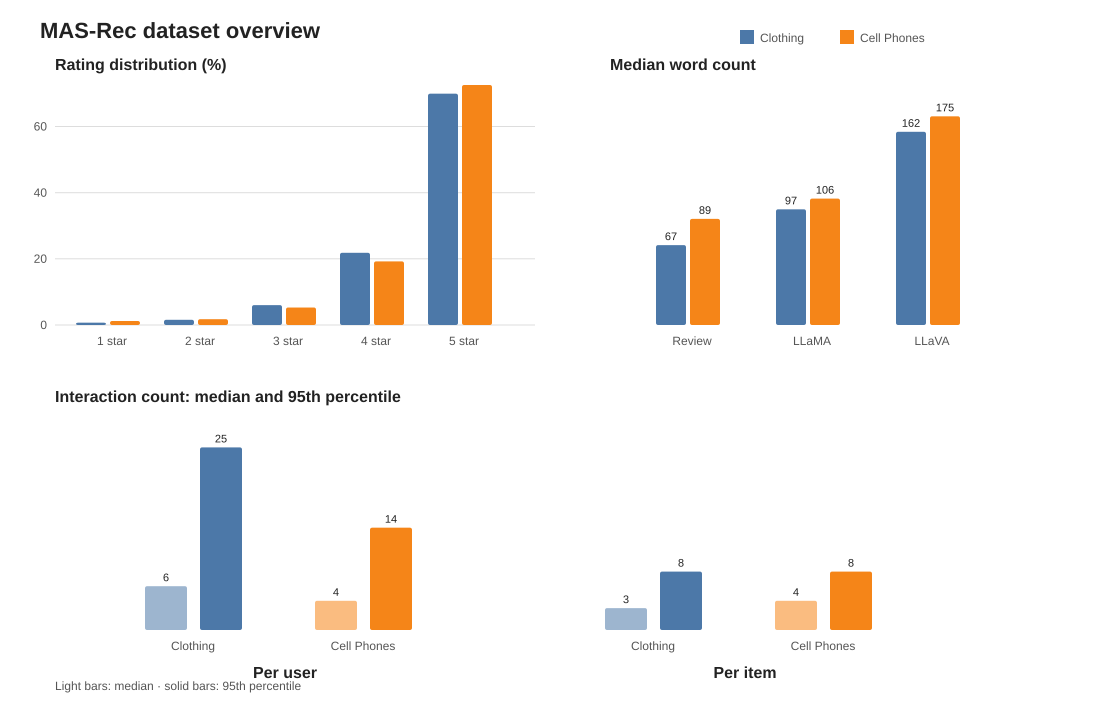

In [6]:
# 주요 분포 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ratings.T.plot(kind='bar', ax=axes[0, 0])
axes[0, 0].set_title('Rating Distribution')
axes[0, 0].set_xlabel('Rating')
axes[0, 0].set_ylabel('Percentage (%)')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

lengths[['review_median', 'llama_median', 'llava_median']].T.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Median Word Count')
axes[0, 1].set_xlabel('Text Type')
axes[0, 1].set_ylabel('Words')
axes[0, 1].tick_params(axis='x', rotation=0)
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

interactions[['user_median', 'user_p95']].T.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Interactions per User')
axes[1, 0].set_xlabel('Statistic')
axes[1, 0].set_ylabel('Interactions')
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

interactions[['item_median', 'item_p95']].T.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Interactions per Item')
axes[1, 1].set_xlabel('Statistic')
axes[1, 1].set_ylabel('Interactions')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 정리

- 두 데이터셋 모두 평점이 높은 쪽으로 치우쳐 있습니다.
- 사용자-상품 행렬은 매우 희소합니다.
- 일부 사용자와 상품에 상호작용이 몰려 있어 단순 무작위 분할은 주의해야 합니다.
- 모델 비교에서는 같은 분할 인덱스와 같은 평가 함수를 사용해야 합니다.
- 이 노트북의 출력은 실제 전체 데이터에서 계산했으며, 원문 리뷰와 사용자 ID는 공개하지 않았습니다.
